---

# DSC Gelar Rasa 2026: Klasifikasi Citra Sampah dengan DINOv3 ViT-7B

*Label train dari cluster yang dinamai tim (notebook v2), lalu satu model DINOv3 ViT-7B yang di-fine-tune dengan LoRA di atas bobot beku terkuantisasi (QLoRA) untuk 8 kategori sampah.*

---

## Nama Tim

- Nama anggota 1
- Nama anggota 2
- Nama anggota 3

---

## Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Pemeriksaan GPU**](#3)
4. [**Data dan Label**](#4)
5. [**Model DINOv3 ViT-7B dengan LoRA**](#5)
6. [**Training**](#6)
7. [**Model Final dan Inference Test**](#7)
8. [**Submission**](#8)
9. [**Validasi Lokal**](#9)
10. [**Pseudo-label Train (Opsional)**](#10)
11. [**Ringkasan Run**](#11)


---

# Pendahuluan <a name="1"></a>

---

## Overview

*Kompetisi meminta klasifikasi citra sampah ke 8 kategori: glass, paper, electronic, metal, plastic, cardboard, textile, dan foodwaste. Data train berisi 1.920 citra tanpa label dan data test berisi 480 citra. Menurut QnA resmi panitia, label train diperoleh lewat clustering dengan model yang dijalankan sendiri, lalu cluster boleh dinamai secara manual.*

## Tujuan

*Notebook ini melatih satu classifier final di atas label train yang sudah final, lalu menulis tepat satu berkas `submission.csv` dari satu model. Clustering dan penamaan cluster tidak diulang di sini.*

## Metrik

***Accuracy** adalah porsi citra test yang kategorinya ditebak benar. Public leaderboard memuat sekitar 30% test (sekitar 145 citra), sehingga satu kesalahan bernilai sekitar 0,7 poin persen. Skor leaderboard tidak dipakai untuk keputusan apa pun di notebook ini.*

$$\text{Accuracy} = \frac{\text{jumlah prediksi benar}}{\text{jumlah citra test}}$$

## Dataset

*Data berasal dari panitia DSC Gelar Rasa 2026 di Kaggle. Train berisi 1.920 citra dalam satu folder tanpa label, test berisi 480 citra. Ekstensi berkas campur, sehingga berkas dicari dari nama (stem) lalu diurutkan sebagai angka. Nama train empat digit (`0001`), nama test tiga digit (`001`).*

*Data dipakai untuk melatih classifier pada train berlabel dan memprediksi test satu kali.*

```
data/
+-- train/                     1.920 citra .jpg/.jpeg, tanpa label
+-- test/                      480 citra .jpg/.jpeg/.png
+-- SampleSubmission_DSC.csv   image_id (3 digit), waste_category
results/
+-- label_train.csv            label final dari notebook v2
```

## Asal Label

*Label train tidak dibuat ulang di notebook ini. Label berasal dari notebook v2 (`notebook/dsc_gelarrasa_2026_dinov3.ipynb`, builder `temp/nb_7b/build_nb.py`, Kaggle `riantamaputra/dsc-gelarrasa-2026-dinov3` versi 4), yang menjalankan seluruh alur pelabelan pada train saja:*

1. *Embedding train dari DINOv3 ViT-L dan DINOv3 ViT-7B. Aturan yang ditetapkan sebelum run memilih ruang ViT-L untuk clustering karena 7B tidak lebih stabil (ARI bootstrap 0,665 lawan 0,692 pada ViT-L).*
2. *KMeans K = 48 pada PCA 128, stabilitas tiap citra dari 20 bootstrap, dan usulan pecah k = 2 per cluster.*
3. *Tim menamai tiap cluster hanya dari montage citra. Enam cluster dinamai per sub-cluster karena berisi dua material: 5, 7, 23, 27, 44, dan 47. Nama tersimpan di `results/nama_cluster_templat.csv`. Ada 5 label tangan: botol kaca Coca-Cola 299, 616, 738, 1060, dan 1192 dari sub-cluster 3a (kaleng, dinamai metal) dilabeli glass.*
4. *Tiga aturan program hanya membuang citra dan tidak pernah memindah kelas: stabilitas nama bootstrap minimal 0,7, minimal separuh dari 10 tetangga terdekat di ruang 7B bernama sama, dan tanpa konflik nama di dalam grup near-duplicate.*

*Hasilnya `results/label_train.csv`: 1.752 dari 1.920 citra berlabel (189 sampai 261 per kelas), 51 citra bernama `campur`, dan 117 citra dibuang aturan. Kolom `grup` adalah grup near-duplicate (pHash dihedral dan cosine embedding) yang dipakai validasi. Isi berkas dikunci dengan hash SHA-256 di Settings, sehingga notebook berhenti bila label berbeda dari versi final. Label yang ada tidak diganti, karena QnA bertentangan soal penggantian label berbasis confidence model (#19.4 membolehkan, #21 melarang).*

## Kepatuhan

| Aturan (nomor pos QnA Padlet) | Penerapan di notebook |
|---|---|
| Tanpa VLM, termasuk image encoder saja (#4, #22.4, #23) | Hanya DINOv3, model self-supervised citra tanpa encoder teks |
| Model pretrained wajib di-fine-tune (#5, #17) | Adapter LoRA di 40 blok dan head dilatih pada train panitia. Model 7B tidak pernah menebak test tanpa fine-tune |
| Label dari clustering, nama cluster manual (#1, #2, #12, #14) | `label_train.csv` dari notebook v2, nama cluster diputuskan tim |
| Buang citra salah cluster dengan aturan program (#19.3) | Tiga aturan buang di notebook v2, tanpa relabel |
| Label tangan maksimal 5 per kelas, total 40 (#22.1) | 5 label tangan, semuanya glass (5 dari 5 per kelas, 5 dari 40 total) |
| Bantuan AI untuk pelabelan dilarang (#16, #20) | Asisten AI hanya memeriksa grid preprocessing setelah nama diputuskan tim. Tidak ada label yang diubah karena pemeriksaan itu |
| Test hanya untuk prediksi akhir (#24) | Piksel test baru dibaca di bagian 7. Tidak ada fitting, normalisasi, atau pseudo-label dari test. Mean dan std memakai konstanta ImageNet bawaan bobot |
| Tanpa dataset eksternal (#22.6) | Hanya data panitia. Bobot pretrained non-VLM diperbolehkan (#5) |
| Pseudo-label hanya dari train (#22.3) | Opsional, hanya untuk 170 citra train tak berlabel |
| Tanpa ensemble (batasan internal tim) | Satu model final, tanpa rata-rata fold dan tanpa TTA |

## Pendekatan: QLoRA DINOv3 ViT-7B

*DINOv3 ViT-7B/16 adalah vision transformer self-supervised berukuran 6,7 miliar parameter. Bobot pretrained versi timm (`timm/vit_7b_patch16_dinov3.lvd1689m`, revisi dikunci) menjadi base model dan di-fine-tune pada train panitia.*

*Fine-tune penuh tidak muat di GPU yang tersedia. Bobot bf16 saja sudah 13,4 GB, sedangkan AdamW butuh salinan fp32, dua momen, dan gradien, sehingga totalnya di atas 100 GB sebelum aktivasi. Bobot terkuantisasi 4-bit juga tidak bisa diperbarui dengan gradien. Karena itu bobot 7B dibekukan, dalam NF4 4-bit di GPU 32 GB atau bf16 di GPU 96 GB, dan yang dilatih hanya adapter LoRA rank 16 di kelima lapis linear setiap blok beserta head linear 8 kelas. Pola ini disebut QLoRA bila base model terkuantisasi.*

```
citra -> trim pita hitam -> stretch 512 x 512 -> augmentasi -> 384 x 384
    |
    +-- DINOv3 ViT-7B/16: 40 blok, dimensi 4096, bobot beku (NF4 atau bf16)
    |     +-- LoRA r = 16 pada qkv, proj, fc1_g, fc1_x, fc2 di setiap blok (39,3 juta parameter latih)
    |
    +-- fitur: token CLS (4096) + rata-rata 576 patch token (4096) = 8192
    |
    Linear 8192 -> 8 kelas -> softmax
```

*Head diinisialisasi dari linear probe (regresi logistik pada fitur beku), lalu LoRA dan head dilatih bersama selama 4 epoch dengan AdamW, warmup lalu cosine, label smoothing 0,1, bobot kelas akar-invers, dan gradient checkpointing per blok. Semua hyperparameter ditetapkan sebelum run. Submission berasal dari satu model yang dilatih pada seluruh 1.750 citra berlabel, ditulis sebelum cross-validation. Model fold hanya untuk mengukur dan tidak dirata-rata.*

---

# Inisialisasi <a name="2"></a>

---

## Environment Setup

Notebook ditujukan untuk Jupyter di Vast.ai dengan satu GPU Blackwell: RTX 5090 (32 GB) atau RTX PRO 6000 (96 GB). Pilih template PyTorch dengan CUDA 12.8 atau lebih baru, karena arsitektur sm_120 butuh PyTorch 2.7 ke atas build cu128. Siapkan disk minimal 80 GB, karena bobot resmi 7B berukuran 26,9 GB (fp32) dan diunduh sekali ke cache Hugging Face. Clone repo ke instance, lalu buka notebook dari folder `notebook/`. Notebook mencari `data/SampleSubmission_DSC.csv` dan `results/label_train.csv` di folder kerja, folder induknya, atau `/workspace`. Keluaran ditulis ke `keluaran_7b/` di folder kerja, atau ke folder di variabel lingkungan `DSC_KELUARAN`.

Token Hugging Face tidak wajib karena repo bobot timm tidak gated. Bila ada, token dibaca dari variabel lingkungan `HF_TOKEN` atau dari berkas `.env` di root repo (baris `HF_TOKEN=...`), dan nilainya tidak pernah dicetak. Perkiraan kasar di RTX 5090: unduh dan muat bobot 10 sampai 15 menit, fitur beku sekitar 3 menit, model final 4 epoch di 384 px sekitar 40 menit. Angka pastinya dicetak dari uji 1 batch di bagian 5. Bila kernel mati, jalankan ulang semua sel: training model final dilanjutkan dari checkpoint epoch terakhir, dan fold cross-validation yang selesai dimuat dari disk.

In [1]:
!nvidia-smi

Sat Nov 14 10:09:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        On  |   00000000:01:00.0 Off |                  N/A |
|100%   27C    P8             32W /  500W |       2MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Sel berikut memasang pustaka yang belum ada di image PyTorch, dengan versi yang sudah diuji. timm dipasang tanpa dependensi supaya pip tidak mengganti torch atau torchvision bawaan image, yang sudah cocok dengan driver GPU.

In [2]:
%pip install -q --no-deps timm==1.0.29
%pip install -q peft==0.21.3 bitsandbytes==0.50.2 accelerate==1.15.0 safetensors huggingface_hub pyyaml scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Semua import dikumpulkan di satu sel.

In [3]:
import gc
import hashlib
import json
import math
import os
import platform
import random
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

# harus sebelum import torch: import bitsandbytes sudah menginisialisasi CUDA dan allocator-nya
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')

import bitsandbytes as bnb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from accelerate import init_empty_weights
from accelerate.utils import set_module_tensor_to_device
from huggingface_hub import hf_hub_download
from huggingface_hub.constants import HF_HUB_CACHE
from IPython.display import display
from peft import LoraConfig, inject_adapter_in_model
from PIL import Image, ImageOps
from safetensors import safe_open
from safetensors.torch import save_file
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.checkpoint import checkpoint
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2 as T

print('torch', torch.__version__, '| timm', timm.__version__, '| peft', peft.__version__, '| bitsandbytes', bnb.__version__)

torch 2.14.1+cu130 | timm 1.0.29 | peft 0.21.3 | bitsandbytes 0.50.2


## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # cuDNN deterministik membuat training notebook v2 sekitar 30x lebih lambat, jadi hanya seed yang dikunci
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False


def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


seed_everything(42)

## Settings

Semua path, revisi bobot, hyperparameter, batas waktu, dan flag dikumpulkan di sini. Parameter preprocessing berasal dari verifikasi lokal `temp/prep_302_verifikasi_run1`. Hyperparameter training ditetapkan sebelum run dan tidak disetel terhadap skor apa pun. `MUAT = 'auto'` memakai bf16 bila VRAM minimal 60 GiB dan NF4 bila kurang. `UKURAN_CADANGAN` dan `BS_MIKRO` adalah urutan fallback bila 384 px atau batch 16 tidak muat di VRAM atau melewati `BATAS_FINAL_JAM`. Batch efektif tetap 16 lewat gradient accumulation. `STAB_MIN` dan `KNN_MIN` hanya dipakai untuk melaporkan alasan pembuangan label dari notebook v2.

In [5]:
def cari_berkas(nama):
    for akar in (Path.cwd(), Path.cwd().parent, Path('/workspace')):
        for pola in (nama, f'*/{nama}', f'*/*/{nama}'):
            hit = sorted(akar.glob(pola))
            if hit:
                return hit[0].resolve()
    raise FileNotFoundError(f'{nama} tidak ditemukan di folder kerja, folder induk, atau /workspace')


def pasang_token():
    if os.environ.get('HF_TOKEN'):
        return 'variabel lingkungan'
    for f in (Path.cwd() / '.env', Path.cwd().parent / '.env', Path('/workspace/.env')):
        if f.is_file():
            for baris in f.read_text(encoding='utf-8').splitlines():
                kunci, _, nilai = baris.partition('=')
                if kunci.strip().removeprefix('export ').strip() == 'HF_TOKEN' and nilai.strip():
                    os.environ['HF_TOKEN'] = nilai.strip().strip('\'"')
                    return f'berkas {f}'
    return None


class Settings:
    SEED = 42
    KELAS = ['glass', 'paper', 'electronic', 'metal', 'plastic', 'cardboard', 'textile', 'foodwaste']
    SUB_PATH = cari_berkas('SampleSubmission_DSC.csv')
    LABEL_PATH = cari_berkas('label_train.csv')
    LABEL_SHA256 = '3e1ebd5007cb6fccf57ee4eb7468a2bb6eca55c5bf065e139025967b81ed00f5'
    OUTPUT_DIR = Path(os.environ.get('DSC_KELUARAN', Path.cwd() / 'keluaran_7b'))
    FIG_DIR = OUTPUT_DIR / 'gambar'
    STAB_MIN = 0.7
    KNN_MIN = 0.5

    M7B = ('timm/vit_7b_patch16_dinov3.lvd1689m', 'b40f6c827cb02b13c7a23a76cf598489bb0f94e5', 'vit_7b_patch16_dinov3')
    DISK_MIN_GIB = 30
    MUAT = 'auto'
    VRAM_BF16_GIB = 60
    LORA_R = 16
    LORA_ALPHA = 32
    LORA_DROPOUT = 0.05
    LORA_TARGET = r'blocks\.\d+\.(attn\.(qkv|proj)|mlp\.(fc1_g|fc1_x|fc2))'

    UKURAN_SIMPAN = 512
    UKURAN = 384
    UKURAN_CADANGAN = (320, 256, 224)
    MEAN = (0.485, 0.456, 0.406)
    STD = (0.229, 0.224, 0.225)
    RRC_SCALE = (0.5, 1.0)
    JITTER = (0.2, 0.1)
    TRIM = (12, 4, 0.03)

    BS = 16
    BS_MIKRO = (16, 8, 4, 2)
    EPOCH = 4
    LR_LORA = 1e-4
    LR_KEPALA = 1e-3
    WD = 0.05
    WARMUP = 0.1
    SMOOTH = 0.1
    LP_C = 0.1
    LP_MIN = 0.8
    VRAM_MAKS = 0.85
    BATAS_FINAL_JAM = 1.5
    JALANKAN_CV = True
    N_FOLD = 5
    MIN_FOLD = 2
    BATAS_CV_JAM = 2.0
    JALANKAN_PSEUDO = False
    AMBANG_PSEUDO = 0.85
    # /dev/shm bawaan Docker hanya 64 MB, terlalu kecil untuk batch yang dikirim worker DataLoader
    SHM_GIB = shutil.disk_usage('/dev/shm').free / 2**30 if Path('/dev/shm').exists() else 0.0
    NUM_WORKERS = min(8, os.cpu_count() or 1) if SHM_GIB >= 2 else 0


CFG = Settings()
for d in (CFG.OUTPUT_DIR, CFG.FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
sumber_token = pasang_token()
print('data:', CFG.SUB_PATH.parent, '| label:', CFG.LABEL_PATH, '| keluaran:', CFG.OUTPUT_DIR)
print(f'/dev/shm bebas {CFG.SHM_GIB:.1f} GiB -> worker DataLoader {CFG.NUM_WORKERS}')
print('HF_TOKEN:', f'terpasang dari {sumber_token}' if sumber_token else 'tidak ada, repo timm tidak gated sehingga unduhan tetap jalan')

data: /workspace/data | label: /workspace/label_train.csv | keluaran: /workspace/keluaran_7b
/dev/shm bebas 15.0 GiB -> worker DataLoader 8
HF_TOKEN: tidak ada, repo timm tidak gated sehingga unduhan tetap jalan


## Load Dataset

Berkas citra dikumpulkan dari nama (stem) lalu diurutkan sebagai angka karena ekstensinya campur. Label dibaca dari `label_train.csv`, diperiksa hash-nya, lalu diselaraskan dengan urutan berkas train. Bagian ini belum membaca piksel.

In [6]:
EKSTENSI = ('.jpg', '.jpeg', '.png')
TRAIN_DIR = next(p for p in sorted(CFG.SUB_PATH.parent.rglob('train')) if p.is_dir())
TEST_DIR = next(p for p in sorted(CFG.SUB_PATH.parent.rglob('test')) if p.is_dir())
f_train = sorted((p for p in TRAIN_DIR.iterdir() if p.suffix.lower() in EKSTENSI), key=lambda p: int(p.stem))
f_test = sorted((p for p in TEST_DIR.iterdir() if p.suffix.lower() in EKSTENSI), key=lambda p: int(p.stem))
id_train = np.array([int(p.stem) for p in f_train])
id_test = np.array([int(p.stem) for p in f_test])
assert len(f_train) == 1920 and len(f_test) == 480, (len(f_train), len(f_test))
assert len(set(id_train)) == 1920 and len(set(id_test)) == 480, 'stem ganda'

LABEL = pd.read_csv(CFG.LABEL_PATH)
kanon = LABEL[['image_id', 'nama', 'berlabel', 'grup']].to_csv(index=False, lineterminator='\n')
assert hashlib.sha256(kanon.encode()).hexdigest() == CFG.LABEL_SHA256, 'label_train.csv berbeda dari versi final notebook v2'
LABEL = LABEL.set_index('image_id').loc[id_train].reset_index()
BERLABEL = LABEL.berlabel.to_numpy(bool)
L = np.flatnonzero(BERLABEL)
U = np.flatnonzero(~BERLABEL)
Y = np.array([CFG.KELAS.index(n) for n in LABEL.nama.to_numpy()[L]])
GRUP = LABEL.grup.to_numpy()
print(f'train {len(f_train)} | test {len(f_test)} | berlabel {len(L)} | tak berlabel {len(U)} | '
      f'grup near-duplicate {len(np.unique(GRUP))}')

train 1920 | test 480 | berlabel 1752 | tak berlabel 168 | grup near-duplicate 1396


---

# Pemeriksaan GPU <a name="3"></a>

---

Blackwell (RTX 5090 dan RTX PRO 6000, kapabilitas sm_120) hanya didukung PyTorch 2.7 ke atas build CUDA 12.8 dan bitsandbytes yang membawa kernel sm_120. Sel berikut mencetak versi semua komponen, memeriksa apakah build PyTorch memuat kernel untuk GPU ini, lalu menjalankan forward dan backward kecil untuk matmul bf16, scaled dot-product attention, dan lapis linear NF4. Bila salah satu gagal, sel berhenti dengan perintah perbaikannya. Mode bobot 7B dipilih dari VRAM: bf16 tanpa kuantisasi bila VRAM minimal 60 GiB, NF4 bila kurang.

In [7]:
assert torch.cuda.is_available(), 'CUDA tidak tersedia: pilih instance GPU dengan image PyTorch build CUDA'
DEV = torch.device('cuda:0')
prop = torch.cuda.get_device_properties(DEV)
VRAM_GIB = prop.total_memory / 2**30
SM = f'sm_{prop.major}{prop.minor}'
INFO_GPU = {'gpu': prop.name, 'kapabilitas': SM, 'vram_gib': round(VRAM_GIB, 1), 'python': platform.python_version(),
            'torch': torch.__version__, 'cuda_torch': torch.version.cuda, 'cudnn': torch.backends.cudnn.version(),
            'bitsandbytes': bnb.__version__, 'timm': timm.__version__, 'peft': peft.__version__,
            'arsitektur_build': ' '.join(torch.cuda.get_arch_list())}
display(pd.Series(INFO_GPU, dtype=object).to_frame('nilai'))
if SM not in torch.cuda.get_arch_list():
    print(f'PERINGATAN: build PyTorch ini tidak memuat kernel {SM}. Untuk Blackwell jalankan '
          '%pip install -U torch torchvision --index-url https://download.pytorch.org/whl/cu128 lalu restart kernel.')


def uji_kernel():
    x = torch.randn(4, 64, 256, device=DEV, requires_grad=True)
    lin = nn.Linear(256, 768).to(DEV)
    with torch.autocast('cuda', dtype=torch.bfloat16):
        q, k, v = lin(x).view(4, 64, 3, 4, 64).unbind(2)
        y = F.scaled_dot_product_attention(q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2))
    y.float().sum().backward()
    q4 = bnb.nn.Linear4bit(256, 512, compute_dtype=torch.bfloat16, quant_type='nf4')
    q4.load_state_dict(nn.Linear(256, 512).state_dict())
    q4 = q4.to(DEV)
    x4 = torch.randn(8, 256, device=DEV, requires_grad=True)
    q4(x4).float().sum().backward()
    torch.cuda.synchronize()
    return bool(torch.isfinite(x.grad).all() and torch.isfinite(x4.grad).all())


try:
    print('uji forward + backward bf16, SDPA, dan NF4:', 'OK' if uji_kernel() else 'GAGAL, nilai non-finite')
except Exception as e:
    raise RuntimeError('Kernel GPU gagal. Blackwell butuh PyTorch >= 2.7 cu128 '
                       '(%pip install -U torch torchvision --index-url https://download.pytorch.org/whl/cu128) '
                       'dan bitsandbytes >= 0.46, lalu restart kernel.') from e
MUAT = CFG.MUAT if CFG.MUAT != 'auto' else ('bf16' if VRAM_GIB >= CFG.VRAM_BF16_GIB else 'nf4')
bebas, total = torch.cuda.mem_get_info(DEV)
print(f'mode bobot 7B: {MUAT} | VRAM bebas {bebas / 2**30:.1f} dari {total / 2**30:.1f} GiB')

,nilai
gpu,NVIDIA GeForce RTX 5090
kapabilitas,sm_120
vram_gib,31.4
python,3.12.15
torch,2.14.1+cu130
cuda_torch,13.0
cudnn,92400
bitsandbytes,0.50.2
timm,1.0.29
peft,0.21.3


uji forward + backward bf16, SDPA, dan NF4: OK
mode bobot 7B: nf4 | VRAM bebas 30.7 dari 31.4 GiB


---

# Data dan Label <a name="4"></a>

---

Bagian ini memeriksa label final, memuat piksel train dengan preprocessing yang sama seperti notebook v2, lalu menampilkan seluruh citra train per kelas dan contoh augmentasi. Piksel test belum dibaca.

## Sebaran Label

Tabel memisahkan citra berlabel, citra bernama `campur`, dan citra bernama yang dibuang aturan program notebook v2. Kolom `stab_nama`, `knn_nama`, dan `konflik_grup` berasal dari berkas label dan hanya dipakai untuk laporan.

nama,glass,paper,electronic,metal,plastic,cardboard,textile,foodwaste,campur
status,,,,,,,,,
berlabel,207,213,189,198,261,236,209,239,0
campur,0,0,0,0,0,0,0,0,51
dibuang aturan,8,10,24,8,32,17,9,9,0


dibuang aturan 117: stab_nama < 0.7 95, knn_nama < 0.5 50, konflik grup 0
grup near-duplicate: 1396 grup, 208 grup berisi lebih dari 1 citra, terbesar 50


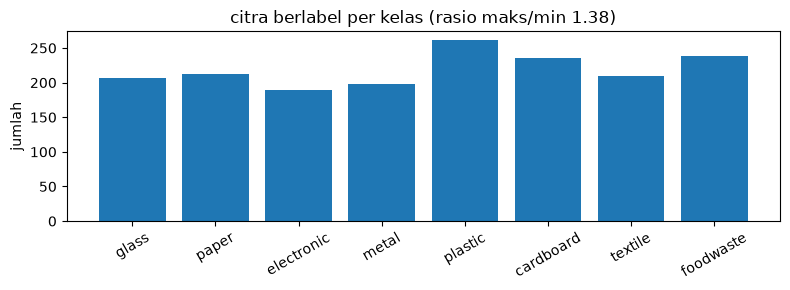

In [8]:
status = np.where(BERLABEL, 'berlabel', np.where(LABEL.nama.eq('campur'), 'campur', 'dibuang aturan'))
display(pd.crosstab(LABEL.nama, status, colnames=['status']).reindex(CFG.KELAS + ['campur']).fillna(0).astype(int).T)
dibuang = LABEL[status == 'dibuang aturan']
print(f'dibuang aturan {len(dibuang)}: stab_nama < {CFG.STAB_MIN} {int((dibuang.stab_nama < CFG.STAB_MIN).sum())}, '
      f'knn_nama < {CFG.KNN_MIN} {int((dibuang.knn_nama < CFG.KNN_MIN).sum())}, konflik grup {int(dibuang.konflik_grup.sum())}')
uk = pd.Series(GRUP).value_counts()
print(f'grup near-duplicate: {len(uk)} grup, {int((uk > 1).sum())} grup berisi lebih dari 1 citra, terbesar {uk.max()}')
n_kelas = np.bincount(Y, minlength=len(CFG.KELAS))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(CFG.KELAS, n_kelas, color='C0')
ax.set(title=f'citra berlabel per kelas (rasio maks/min {n_kelas.max() / n_kelas.min():.2f})', ylabel='jumlah')
ax.tick_params(axis='x', labelrotation=30)
plt.tight_layout()
fig.savefig(CFG.FIG_DIR / 'sebaran_label.png', dpi=100)
plt.show()

#### Insights

> Kelas cukup seimbang, 189 sampai 261 citra per kelas (rasio 1,38). Bobot kelas akar-invers frekuensi dipakai sebagai koreksi ringan di loss. Electronic paling banyak kehilangan citra karena beberapa cluster electronic saling bertukar anggota antar bootstrap.

> Grup near-duplicate menyatukan salinan hasil flip, rotasi, atau unggah ulang. Validasi memakai grup ini supaya salinan sebuah citra tidak muncul di train dan validasi sekaligus.

## Preprocessing

Setiap citra train dibuka sekali: orientasi EXIF diterapkan, mode dikonversi ke RGB (ada PNG mode P dan RGBA), pita hitam murni dari sumber dipotong, lalu di-stretch bicubic ke 512 x 512 dan disimpan di RAM (sekitar 1,5 GB). Fungsinya identik dengan notebook v2 dan `temp/prep_302_verifikasi_run1/pipa.py`. Letterbox ditolak karena pita hitamnya terkumpul di kelas electronic dan menjadi jalan pintas. Denoise juga tidak dipakai karena tekstur adalah isyarat material.

In [9]:
def trim_hitam(a, ambang=CFG.TRIM[0], std_maks=CFG.TRIM[1], porsi_min=CFG.TRIM[2]):
    g = a.max(2).astype(np.float32)

    def tepi(pmax, pstd):
        n = 0
        while n < len(pmax) and pmax[n] < ambang and pstd[n] < std_maks:
            n += 1
        return n

    rmax, rstd, cmax, cstd = np.percentile(g, 99, axis=1), g.std(1), np.percentile(g, 99, axis=0), g.std(0)
    t, b, l, r = tepi(rmax, rstd), tepi(rmax[::-1], rstd[::-1]), tepi(cmax, cstd), tepi(cmax[::-1], cstd[::-1])
    H, W = g.shape
    t, b = (t, b) if (t + b) / H >= porsi_min else (0, 0)
    l, r = (l, r) if (l + r) / W >= porsi_min else (0, 0)
    if H - t - b < H * .3 or W - l - r < W * .3:
        return a
    return a[t:H - b, l:W - r]


def muat_citra(p):
    with Image.open(p) as im:
        a = trim_hitam(np.asarray(ImageOps.exif_transpose(im).convert('RGB')))
    return np.asarray(Image.fromarray(a).resize((CFG.UKURAN_SIMPAN, CFG.UKURAN_SIMPAN), Image.BICUBIC))


t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    X_train = np.stack(list(ex.map(muat_citra, f_train)))
print(f'X_train {X_train.shape}, {X_train.nbytes / 2**30:.2f} GiB, {time.time() - t0:.0f} detik')

X_train (1920, 512, 512, 3), 1.41 GiB, 4 detik


## Montage Seluruh Train per Kelas

Montage memuat semua citra train setelah preprocessing, dikelompokkan menurut label final, ditambah satu montage untuk 170 citra tak berlabel. Montage ini adalah bukti visual label dan alat pemeriksaan preprocessing. Montage tidak dipakai untuk mengubah label. Salinannya disimpan di `gambar/montage_<kelas>.jpg`.

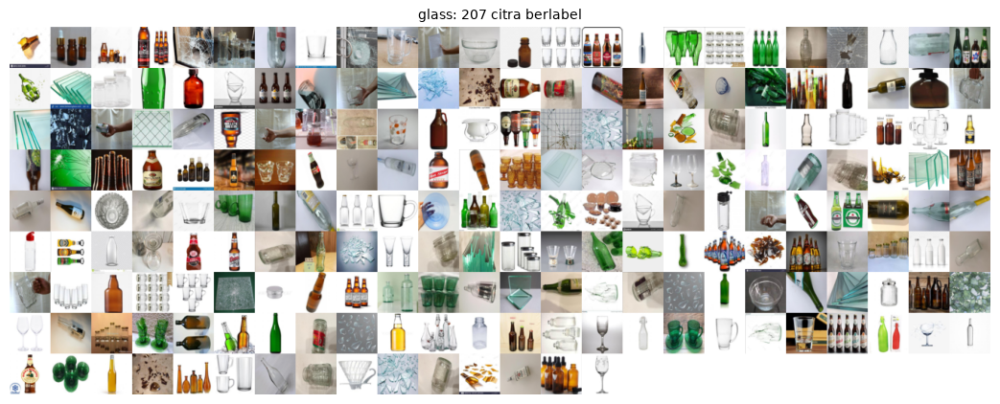

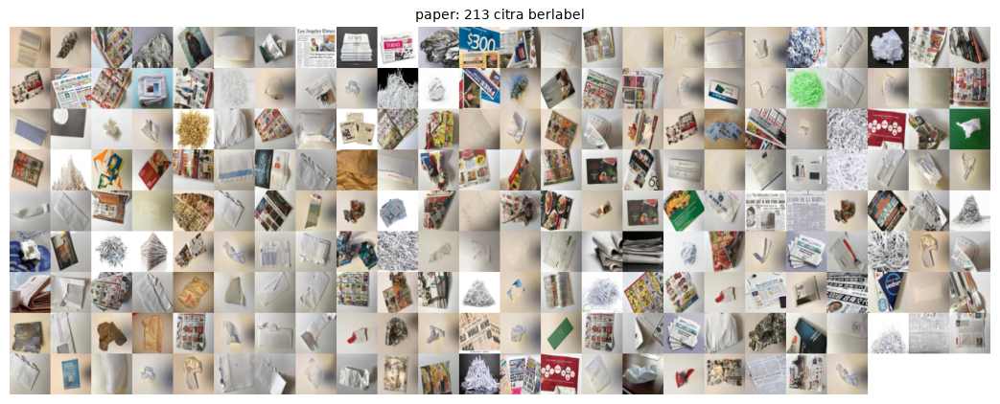

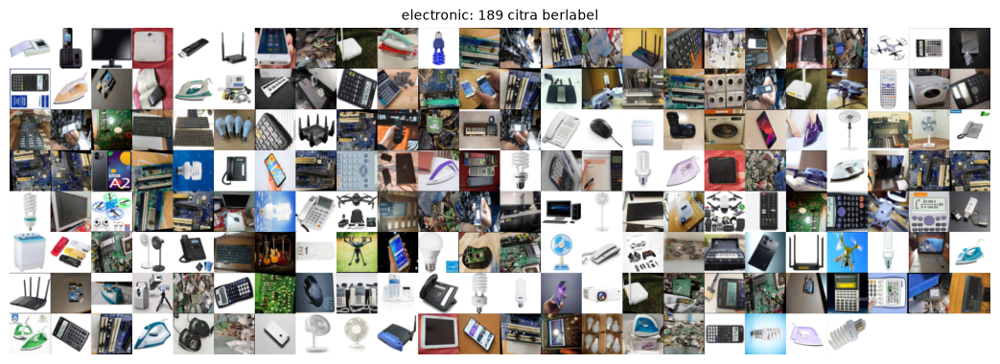

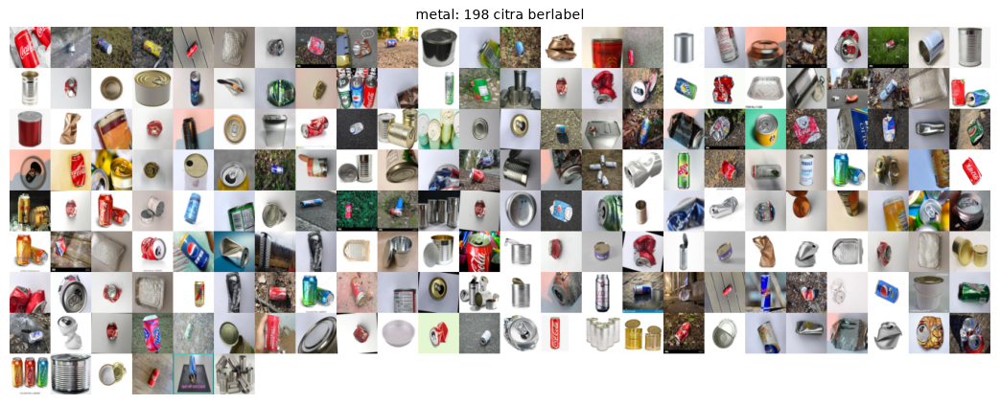

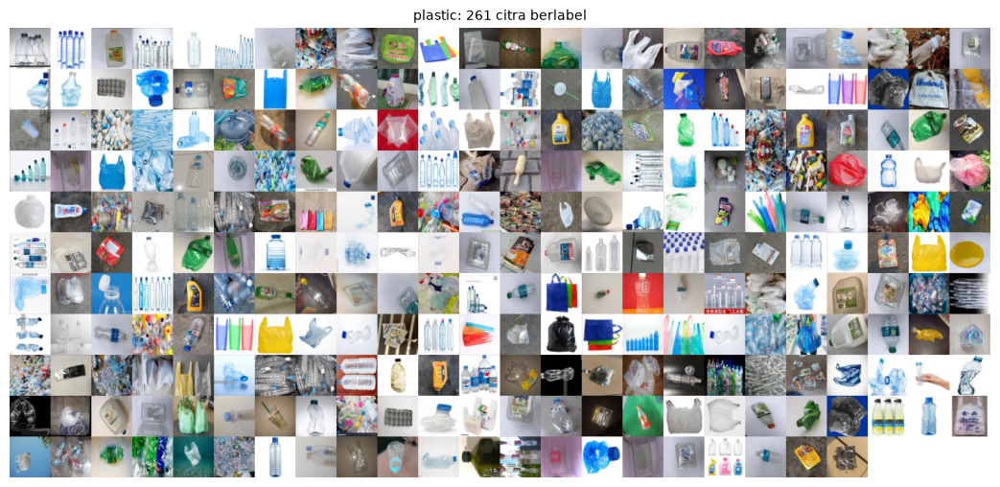

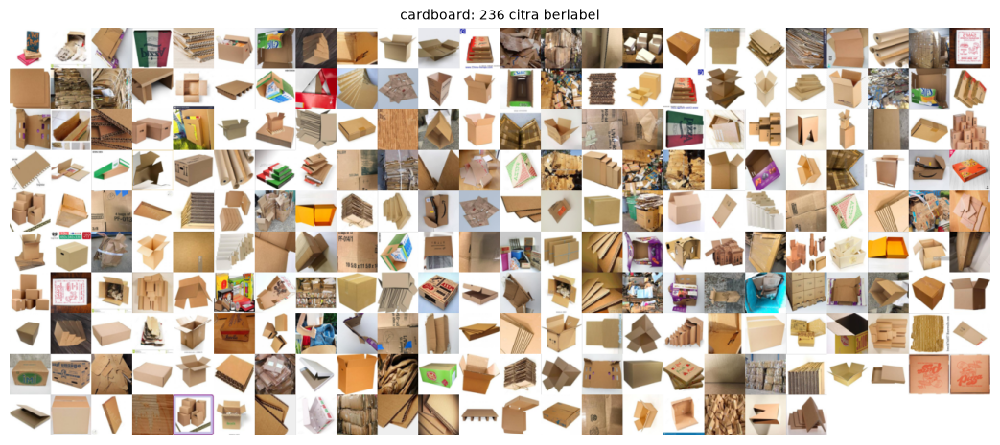

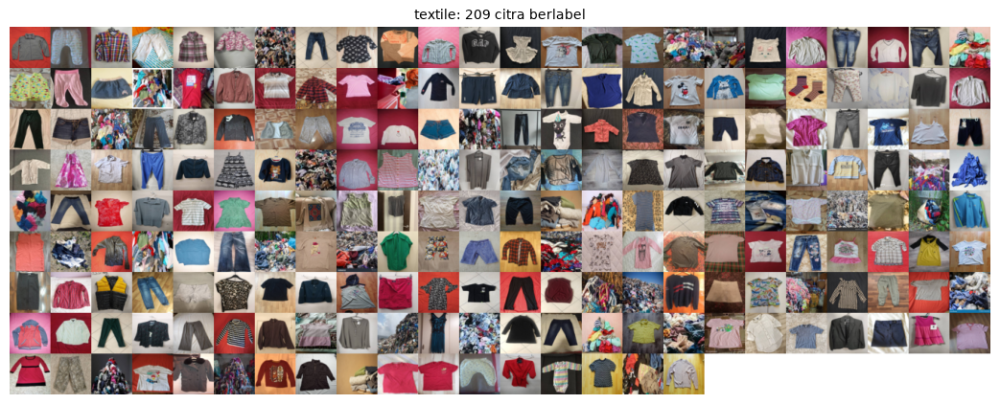

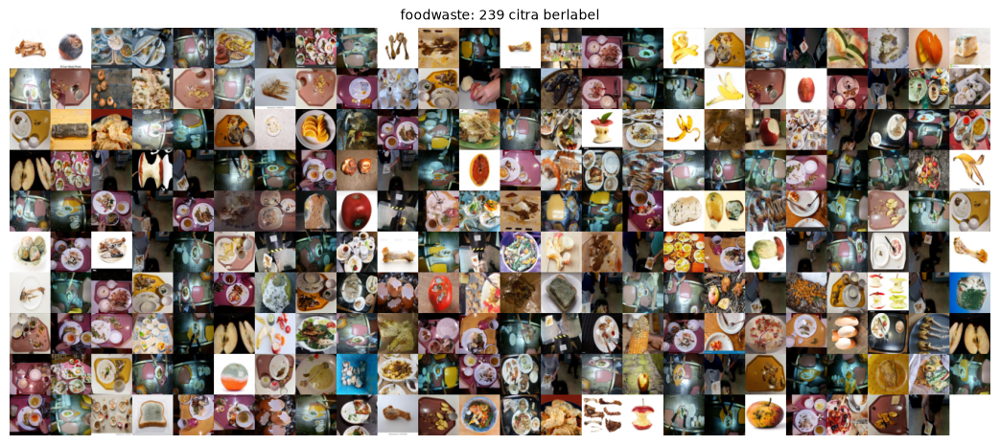

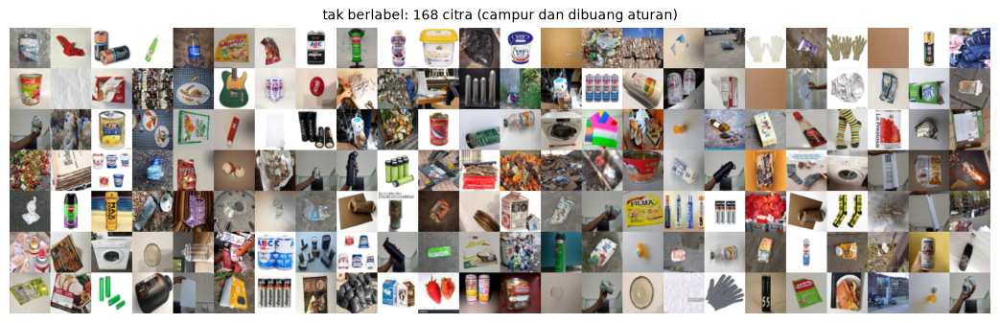

In [10]:
def montage(idx, judul, berkas, kol=24, uk=56):
    baris = math.ceil(len(idx) / kol)
    kanvas = Image.new('RGB', (kol * uk, baris * uk), (255, 255, 255))
    for j, i in enumerate(idx):
        kanvas.paste(Image.fromarray(X_train[i]).resize((uk, uk), Image.BILINEAR), (j % kol * uk, j // kol * uk))
    kanvas.save(CFG.FIG_DIR / berkas, quality=85)
    plt.figure(figsize=(kol * 0.55, baris * 0.55 + 0.5))
    plt.imshow(kanvas)
    plt.axis('off')
    plt.title(judul, fontsize=10)
    plt.show()


for k, kls in enumerate(CFG.KELAS):
    montage(L[Y == k], f'{kls}: {int((Y == k).sum())} citra berlabel', f'montage_{kls}.jpg')
montage(U, f'tak berlabel: {len(U)} citra (campur dan dibuang aturan)', 'montage_tak_berlabel.jpg')

#### Insights

> Pemeriksaan lokal atas seluruh 1.920 citra (montage per kelas dan grid augmentasi di `temp/nb_7b_qlora/output`, dibuat dengan fungsi preprocessing yang sama) hanya menilai preprocessing dan dilakukan setelah nama cluster diputuskan tim. Orientasi EXIF benar, 123 citra yang pita hitamnya dipotong tidak menyisakan pita, dan objek pada citra beraspek ekstrem memanjang tetapi tetap utuh. Tidak ada citra yang dilabeli, dipindah, atau dibuang berdasarkan pemeriksaan ini, sesuai QnA #16 dan #20.

> Watermark situs stok foto, bingkai bawaan sumber, dan sudut gelap melingkar dari lensa fisheye pada foto nampan makanan adalah sifat sumber, bukan hasil preprocessing. Trim hanya memotong baris atau kolom tepi yang hitam seragam, jadi sudut gelap fisheye tidak ikut terpotong. Sebanyak 105 citra bersisi pendek di bawah 200 px tampak buram setelah upscale, tetapi isinya tetap terbaca.

## Augmentasi

Parameter augmentasi dipilih lewat iterasi lokal `prep_301` dan `prep_302` dengan kriteria yang ditetapkan sebelum pengukuran: RandomResizedCrop dengan luas minimum 0,5 (scale 0,4 membuang objek kecil di latar polos pada 10,05% crop, di atas batas 10%), flip horizontal dan vertikal, rotasi kelipatan 90 derajat yang meniru salinan dihedral di data, serta jitter brightness 0,2 dan contrast 0,1 tanpa saturation dan hue supaya warna cardboard tidak bergeser ke paper. Rotasi kecil ditolak karena sudut isiannya mencolok. `transform` dibuat sebagai fungsi karena resolusi bisa turun lewat fallback di bagian 5. Grid menampilkan satu citra per kelas: asli, setelah trim dan stretch, lalu tiga hasil augmentasi train.

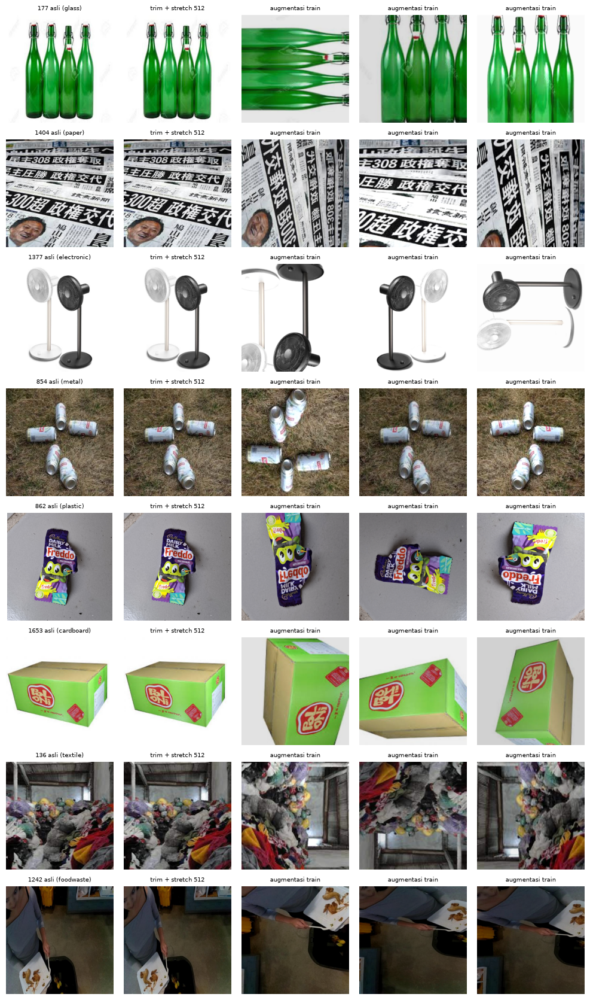

In [11]:
def transform(ukuran):
    aug = [T.RandomResizedCrop(ukuran, scale=CFG.RRC_SCALE, ratio=(3 / 4, 4 / 3), antialias=True),
           T.RandomHorizontalFlip(),
           T.RandomVerticalFlip(),
           T.RandomChoice([T.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
           T.ColorJitter(brightness=CFG.JITTER[0], contrast=CFG.JITTER[1])]
    normal = [T.ToDtype(torch.float32, scale=True), T.Normalize(CFG.MEAN, CFG.STD)]
    return (T.Compose([T.ToImage(), *aug, *normal]),
            T.Compose([T.ToImage(), T.Resize((ukuran, ukuran), antialias=True), *normal]),
            T.Compose([T.ToImage(), *aug]))


class Citra(Dataset):
    def __init__(self, X, tf, idx=None, y=None):
        self.X, self.tf, self.y = X, tf, y
        self.idx = np.arange(len(X)) if idx is None else np.asarray(idx)

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        x = self.tf(self.X[self.idx[i]])
        return x if self.y is None else (x, int(self.y[i]))


UKURAN = CFG.UKURAN
tf_train, tf_eval, tf_tampil = transform(UKURAN)
rng = np.random.default_rng(CFG.SEED)
fig, ax = plt.subplots(len(CFG.KELAS), 5, figsize=(10, 2.1 * len(CFG.KELAS)))
for r, k in enumerate(range(len(CFG.KELAS))):
    i = rng.choice(L[Y == k])
    with Image.open(f_train[i]) as im:
        ax[r, 0].imshow(ImageOps.exif_transpose(im).convert('RGB'))
    ax[r, 0].set_title(f'{id_train[i]} asli ({CFG.KELAS[k]})', fontsize=7)
    ax[r, 1].imshow(X_train[i])
    ax[r, 1].set_title('trim + stretch 512', fontsize=7)
    for c in range(2, 5):
        ax[r, c].imshow(tf_tampil(X_train[i]).permute(1, 2, 0).numpy())
        ax[r, c].set_title('augmentasi train', fontsize=7)
for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
fig.savefig(CFG.FIG_DIR / 'augmentasi.jpg', dpi=80)
plt.show()

#### Insights

> Augmentasi menjaga isyarat material: crop tidak lebih kecil dari 50% luas, warna kardus tidak dipudarkan lewat saturation, tekstur tidak dihaluskan, dan tidak ada sudut isian yang bisa menjadi artefak. Augmentasi kompresi JPEG dan penurunan resolusi tidak dipakai, karena sumber berkas yang hanya ada di train tidak muncul di test (EDA lokal 212). Evaluasi dan test memakai resize langsung ke 384 x 384 tanpa crop.

---

# Model DINOv3 ViT-7B dengan LoRA <a name="5"></a>

---

Model dibangun dalam empat langkah: unduh bobot resmi timm dengan revisi terkunci, bangun arsitektur kosong lalu isi bobotnya tensor demi tensor (dikuantisasi NF4 atau dikonversi ke bf16 langsung di GPU), pasang LoRA di semua blok, lalu uji satu langkah training untuk memilih resolusi dan batch mikro yang muat. Struktur timm Eva dan pemuatan safetensors ini sama dengan yang sudah berjalan di Run 1 notebook v1 (606 tensor, 0 kunci asing).

## Bobot Pretrained

Bobot diunduh sekali ke cache Hugging Face dengan revisi dikunci. Bila sudah ada di cache, unduhan dilewati. Ruang disk diperiksa lebih dulu karena berkas fp32 berukuran 26,9 GB.

In [12]:
def berkas_bobot():
    repo, rev, _ = CFG.M7B
    try:
        return Path(hf_hub_download(repo, 'model.safetensors', revision=rev, local_files_only=True))
    except Exception:
        Path(HF_HUB_CACHE).mkdir(parents=True, exist_ok=True)
        bebas = shutil.disk_usage(HF_HUB_CACHE).free / 2**30
        assert bebas >= CFG.DISK_MIN_GIB, f'ruang disk {bebas:.0f} GiB, butuh minimal {CFG.DISK_MIN_GIB} GiB untuk bobot fp32 26,9 GB'
        return Path(hf_hub_download(repo, 'model.safetensors', revision=rev))


t0 = time.time()
BERKAS_7B = berkas_bobot()
print(BERKAS_7B, f'{BERKAS_7B.stat().st_size / 1e9:.1f} GB, {time.time() - t0:.0f} detik')

/root/.cache/huggingface/hub/models--timm--vit_7b_patch16_dinov3.lvd1689m/snapshots/b40f6c827cb02b13c7a23a76cf598489bb0f94e5/model.safetensors 26.9 GB, 0 detik


## Muat Bobot Terkuantisasi

Arsitektur dibuat kosong dengan `init_empty_weights`. Pada mode NF4, kelima lapis linear di setiap blok (qkv, proj, fc1_g, fc1_x, fc2, total 200 lapis atau 99,9% dari 6,72 miliar parameter) diganti `bnb.nn.Linear4bit`, lalu setiap bobot dibaca dari safetensors, dikirim ke GPU, dan dikuantisasi NF4 dengan double quantization. Pada mode bf16, bobot yang sama hanya dikonversi ke bf16. Parameter kecil (LayerNorm, LayerScale, bias, token, patch embedding) disimpan dalam fp32 demi kestabilan. RAM tidak pernah menampung seluruh bobot fp32. Semua parameter base model dibekukan.

In [13]:
def muat_7b(berkas, mode):
    with init_empty_weights():
        m = timm.create_model(CFG.M7B[2], pretrained=False, num_classes=0)
    linear = [n for n, mod in m.named_modules() if isinstance(mod, nn.Linear) and n.startswith('blocks.')]
    if mode == 'nf4':
        for n in linear:
            lama = m.get_submodule(n)
            induk, anak = n.rsplit('.', 1)
            with init_empty_weights():
                baru = bnb.nn.Linear4bit(lama.in_features, lama.out_features, bias=lama.bias is not None,
                                         compute_dtype=torch.bfloat16, compress_statistics=True, quant_type='nf4')
            setattr(m.get_submodule(induk), anak, baru)
    besar = {f'{n}.weight' for n in linear}
    param = dict(m.named_parameters())
    terisi = set()
    with safe_open(str(berkas), 'pt', device='cpu') as sf:
        for k in sf.keys():
            assert k in param, f'kunci asing di bobot: {k}'
            t = sf.get_tensor(k).to(DEV)
            if mode == 'nf4' and k in besar:
                mod = m.get_submodule(k.rsplit('.', 1)[0])
                mod.weight = bnb.nn.Params4bit(t.to(torch.bfloat16), requires_grad=False, compress_statistics=True,
                                               quant_type='nf4', module=mod).to(DEV)
            else:
                set_module_tensor_to_device(m, k, DEV, value=t, dtype=torch.bfloat16 if k in besar else torch.float32)
            terisi.add(k)
            del t
    kurang = set(param) - terisi
    assert not kurang, f'parameter tanpa bobot: {sorted(kurang)[:5]}'
    for n, b in m.named_buffers():
        set_module_tensor_to_device(m, n, DEV, value=b)
    m.requires_grad_(False)
    return m, len(linear), len(terisi)


torch.cuda.reset_peak_memory_stats(DEV)
t0 = time.time()
m, n_linear, n_tensor = muat_7b(BERKAS_7B, MUAT)
DETIK_MUAT = time.time() - t0
print(f'{CFG.M7B[2]} mode {MUAT}: {n_tensor} tensor, {n_linear} lapis linear, {len(m.blocks)} blok, '
      f'{DETIK_MUAT:.0f} detik, VRAM {torch.cuda.memory_allocated(DEV) / 2**30:.1f} GiB')

vit_7b_patch16_dinov3 mode nf4: 606 tensor, 200 lapis linear, 40 blok, 17 detik, VRAM 3.3 GiB


## Adapter LoRA dan Head

LoRA rank 16 (alpha 32, dropout 0,05) dipasang lewat PEFT pada kelima lapis linear di setiap blok. Pola nama dibatasi ke `blocks.*` supaya konvolusi patch embedding tidak ikut. Parameter LoRA disimpan dalam fp32 sebagai master weight, sedangkan perhitungan berjalan dalam bf16 lewat autocast. Fitur adalah token CLS dan rata-rata patch token setelah LayerNorm akhir (4 token register tidak dipakai). Setiap blok dibungkus gradient checkpointing non-reentrant, sehingga yang disimpan hanya masukan blok dan aktivasi di dalam blok dihitung ulang saat backward. Salinan LoRA awal disimpan supaya setiap training (model final, fold, pseudo-label) mulai dari titik yang sama tanpa memuat ulang 7B.

In [14]:
torch.manual_seed(CFG.SEED)
m = inject_adapter_in_model(LoraConfig(r=CFG.LORA_R, lora_alpha=CFG.LORA_ALPHA, lora_dropout=CFG.LORA_DROPOUT,
                                       bias='none', target_modules=CFG.LORA_TARGET), m)
for n, p in m.named_parameters():
    p.requires_grad_('lora_' in n)
    if 'lora_' in n:
        p.data = p.data.float()
LORA = {n: p for n, p in m.named_parameters() if p.requires_grad}
LORA_AWAL = {n: p.detach().clone() for n, p in LORA.items()}
kepala = nn.Linear(2 * m.embed_dim, len(CFG.KELAS)).to(DEV)
n_modul = sum('lora_A' in n for n in LORA)
assert n_modul == 5 * len(m.blocks), f'LoRA terpasang di {n_modul} lapis, seharusnya {5 * len(m.blocks)}'


def fitur(m, x):
    h = m.patch_embed(x)
    h, rope = m._pos_embed(h)
    h = m.norm_pre(h)
    for blk in m.blocks:
        h = checkpoint(blk, h, rope=rope, use_reentrant=False) if torch.is_grad_enabled() else blk(h, rope=rope)
    h = m.norm(h)
    return torch.cat([h[:, 0], h[:, m.num_prefix_tokens:].mean(1)], 1)


n_latih = sum(p.numel() for p in LORA.values()) + sum(p.numel() for p in kepala.parameters())
print(f'LoRA di {n_modul} lapis linear | parameter latih {n_latih / 1e6:.1f} juta | '
      f'VRAM {torch.cuda.memory_allocated(DEV) / 2**30:.1f} GiB')

LoRA di 200 lapis linear | parameter latih 39.4 juta | VRAM 3.6 GiB


## Uji Satu Langkah dan Fallback

Satu langkah training (forward, backward, tanpa update) dijalankan pada input acak untuk mengukur waktu dan VRAM puncak. Urutannya: 384 px dengan batch mikro 16, 8, 4, lalu 2. Bila semua OOM atau perkiraan waktu model final melewati `BATAS_FINAL_JAM`, resolusi turun ke 320, 256, lalu 224. Konfigurasi dianggap muat bila VRAM puncak paling banyak 85% kapasitas, supaya fragmentasi selama training tidak memicu OOM. Batch efektif tetap 16 lewat gradient accumulation, sehingga resep training tidak berubah.

In [15]:
def uji_langkah(ukuran, bs):
    x = torch.randn(bs, 3, ukuran, ukuran, device=DEV)
    y = torch.zeros(bs, dtype=torch.long, device=DEV)
    m.train()
    torch.cuda.reset_peak_memory_stats(DEV)
    waktu = []
    for _ in range(3):
        torch.cuda.synchronize()
        t0 = time.time()
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = F.cross_entropy(kepala(fitur(m, x)).float(), y)
        loss.backward()
        torch.cuda.synchronize()
        waktu.append(time.time() - t0)
    return min(waktu[1:]), torch.cuda.max_memory_allocated(DEV) / 2**30


def coba(ukuran, bs):
    try:
        return uji_langkah(ukuran, bs)
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        for p in [*LORA.values(), *kepala.parameters()]:
            p.grad = None
        gc.collect()
        torch.cuda.empty_cache()


def pilih_konfigurasi():
    for ukuran in (CFG.UKURAN, *CFG.UKURAN_CADANGAN):
        for bs in CFG.BS_MIKRO:
            h = coba(ukuran, bs)
            if h is None:
                print(f'{ukuran} px, batch mikro {bs}: OOM')
                continue
            detik, vram = h
            per_citra = detik / bs
            # 1,15: cadangan untuk DataLoader, sinkronisasi, dan update optimizer
            jam_final = per_citra * len(L) * CFG.EPOCH * 1.15 / 3600
            print(f'{ukuran} px, batch mikro {bs}: {detik:.2f} detik/langkah, VRAM puncak {vram:.1f} GiB, '
                  f'perkiraan model final {jam_final:.2f} jam')
            if vram > CFG.VRAM_MAKS * VRAM_GIB:
                continue
            if jam_final > CFG.BATAS_FINAL_JAM:
                break
            return dict(ukuran=ukuran, bs_mikro=bs, detik_per_citra=per_citra, vram_gib=round(vram, 1),
                        jam_final=round(jam_final, 2))
    raise RuntimeError('tidak ada konfigurasi yang muat di VRAM dan BATAS_FINAL_JAM; turunkan EPOCH atau naikkan batas')


PILIHAN = pilih_konfigurasi()
UKURAN, BS_MIKRO = PILIHAN['ukuran'], PILIHAN['bs_mikro']
AKUM = CFG.BS // BS_MIKRO
tf_train, tf_eval, tf_tampil = transform(UKURAN)
print(f'dipakai: {UKURAN} px, batch mikro {BS_MIKRO} x akumulasi {AKUM} = batch efektif {BS_MIKRO * AKUM}')
print(f'perkiraan: model final {PILIHAN["jam_final"]:.2f} jam, satu fold CV {PILIHAN["jam_final"] * 0.8 * 1.1:.2f} jam')

384 px, batch mikro 16: 3.71 detik/langkah, VRAM puncak 12.4 GiB, perkiraan model final 0.52 jam
dipakai: 384 px, batch mikro 16 x akumulasi 1 = batch efektif 16
perkiraan: model final 0.52 jam, satu fold CV 0.46 jam


#### Insights

> Isi setelah run: resolusi dan batch mikro terpilih, VRAM puncak, dan perkiraan waktu. Bila resolusi turun dari 384, catat alasannya (OOM atau waktu) di laporan, karena resolusi ikut menentukan detail tekstur yang terlihat model.

---

# Training <a name="6"></a>

---

Training terdiri dari dua tahap. Tahap pertama mengekstrak fitur beku seluruh train sekali (LoRA masih nol, jadi identik dengan base model) dan memakainya untuk dua hal: linear probe sebagai pemeriksaan kewarasan sebelum training panjang, dan inisialisasi head. Tahap kedua melatih LoRA dan head bersama. Fold StratifiedGroupKFold ditetapkan di sini dan dipakai ulang di bagian 9.

## Fitur Beku dan Linear Probe

Regresi logistik (C = 0,1) dilatih pada fitur beku yang dipusatkan dan diskalakan dengan satu konstanta, lalu koefisiennya dilipat menjadi bobot head pada fitur mentah. Skala per dimensi tidak dipakai karena dimensi yang hampir konstan akan menghasilkan bobot sangat besar. Linear probe dinilai dengan StratifiedGroupKFold 5 fold yang sama dengan cross-validation. Bila accuracy rata-ratanya di bawah 0,8, notebook berhenti karena kemungkinan besar ada masalah pemuatan bobot atau preprocessing. Angka ini bukan perkiraan skor test: aturan pembersihan notebook v2 memakai tetangga di ruang 7B, jadi label bersih memang selaras dengan ruang ini.

In [16]:
# Python 3.14 memakai forkserver secara default; worker forkserver tidak bisa memuat kelas yang didefinisikan di notebook
MP_KONTEKS = 'fork' if CFG.NUM_WORKERS else None


@torch.no_grad()
def prediksi(X, idx=None, fitur_saja=False):
    m.eval()
    dl = DataLoader(Citra(X, tf_eval, idx), batch_size=2 * BS_MIKRO, num_workers=CFG.NUM_WORKERS,
                    multiprocessing_context=MP_KONTEKS)
    out = []
    for x in dl:
        with torch.autocast('cuda', dtype=torch.bfloat16):
            f = fitur(m, x.to(DEV, non_blocking=True))
            out.append((f if fitur_saja else torch.softmax(kepala(f).float(), 1)).float().cpu())
    return torch.cat(out).numpy()


def kepala_lp(F_, y):
    mu, s = F_.mean(0), F_.std()
    lr = LogisticRegression(C=CFG.LP_C, max_iter=3000).fit((F_ - mu) / s, y)
    assert len(lr.classes_) == len(CFG.KELAS), 'ada kelas tanpa contoh di data latih'
    W = lr.coef_ / s
    return W.astype(np.float32), (lr.intercept_ - W @ mu).astype(np.float32)


t0 = time.time()
F_TRAIN = prediksi(X_train, fitur_saja=True)
DETIK_FITUR = time.time() - t0
assert np.isfinite(F_TRAIN).all(), 'fitur beku non-finite'

sgkf = StratifiedGroupKFold(n_splits=CFG.N_FOLD, shuffle=True, random_state=CFG.SEED)
FOLD = np.full(len(L), -1)
for f, (_, b) in enumerate(sgkf.split(L, Y, GRUP[L])):
    FOLD[b] = f
assert (FOLD >= 0).all() and (pd.Series(FOLD).groupby(GRUP[L]).nunique() == 1).all(), 'grup terbelah antar fold'

ACC_LP = []
for f in range(CFG.N_FOLD):
    a, b = FOLD != f, FOLD == f
    W, c = kepala_lp(F_TRAIN[L[a]], Y[a])
    ACC_LP.append(float(((F_TRAIN[L[b]] @ W.T + c).argmax(1) == Y[b]).mean()))
print(f'fitur beku {F_TRAIN.shape} dalam {DETIK_FITUR:.0f} detik')
print('ukuran fold:', np.bincount(FOLD).tolist(), '| accuracy linear probe per fold:', np.round(ACC_LP, 4).tolist())
print(f'linear probe: {np.mean(ACC_LP):.4f} +- {np.std(ACC_LP, ddof=1):.4f}')
assert np.mean(ACC_LP) >= CFG.LP_MIN, 'linear probe terlalu rendah: periksa bobot dan preprocessing sebelum training'

fitur beku (1920, 8192) dalam 146 detik
ukuran fold: [351, 350, 350, 351, 350] | accuracy linear probe per fold: [0.9915, 0.9971, 1.0, 0.9915, 0.9914]
linear probe: 0.9943 +- 0.0040


#### Insights

> Isi setelah run: accuracy linear probe per fold dan rata-ratanya. Angka ini menjadi pembanding bagi cross-validation LoRA di bagian 9. Bila LoRA tidak lebih baik dari linear probe, fine-tune tidak menambah informasi di atas fitur beku untuk label ini.

## Fungsi Training

`latih` mengembalikan LoRA ke titik awal, menginisialisasi head dari linear probe pada data latihnya sendiri, lalu melatih LoRA (LR 1e-4) dan head (LR 1e-3) dengan AdamW (weight decay 0,05), warmup linear 10% langkah lalu cosine, cross-entropy dengan label smoothing 0,1 dan bobot kelas akar-invers, gradient clipping 1,0, serta autocast bf16. Bila diberi nama, checkpoint LoRA, head, dan optimizer disimpan tiap epoch dan training lanjut dari sana saat sel dijalankan ulang, asalkan data dan konfigurasinya sama. `latih_aman` mengulang dengan batch mikro setengahnya bila terjadi OOM, dengan batch efektif tetap 16.

In [17]:
def bobot_kelas(y):
    w = 1 / np.sqrt(np.bincount(y, minlength=len(CFG.KELAS)).clip(1))
    return torch.tensor(w / w.mean(), dtype=torch.float32, device=DEV)


def jadwal(langkah, total):
    warm = max(1, int(CFG.WARMUP * total))
    if langkah < warm:
        return (langkah + 1) / warm
    return 0.5 * (1 + math.cos(math.pi * (langkah - warm) / max(1, total - warm)))


def latih(idx, y, idx_va=None, y_va=None, nama=None):
    seed_everything(CFG.SEED)
    W, c = kepala_lp(F_TRAIN[idx], y)
    with torch.no_grad():
        for n, p in LORA.items():
            p.copy_(LORA_AWAL[n])
        kepala.weight.copy_(torch.from_numpy(W))
        kepala.bias.copy_(torch.from_numpy(c))
    dl = DataLoader(Citra(X_train, tf_train, idx, y), batch_size=BS_MIKRO, shuffle=True, drop_last=True,
                    num_workers=CFG.NUM_WORKERS, worker_init_fn=seed_worker, pin_memory=True,
                    multiprocessing_context=MP_KONTEKS, generator=torch.Generator().manual_seed(CFG.SEED),
                    persistent_workers=CFG.NUM_WORKERS > 0)
    per_epoch = len(dl) // AKUM
    total = per_epoch * CFG.EPOCH
    opt = torch.optim.AdamW([{'params': list(LORA.values()), 'lr': CFG.LR_LORA},
                             {'params': list(kepala.parameters()), 'lr': CFG.LR_KEPALA}], weight_decay=CFG.WD)
    lr_dasar = [g['lr'] for g in opt.param_groups]
    kriteria = nn.CrossEntropyLoss(weight=bobot_kelas(y), label_smoothing=CFG.SMOOTH)
    resep = (UKURAN, CFG.BS, CFG.EPOCH, CFG.LR_LORA, CFG.LR_KEPALA, CFG.WD, CFG.LORA_R, CFG.LORA_ALPHA, MUAT)
    kunci = hashlib.sha256(np.asarray(idx).tobytes() + np.asarray(y).tobytes() + repr(resep).encode()).hexdigest()[:16]
    jalur = CFG.OUTPUT_DIR / f'ckpt_{nama}.pt' if nama else None
    mulai, langkah, riwayat, pv = 0, 0, [], None
    if jalur and jalur.exists():
        s = torch.load(jalur, map_location='cpu', weights_only=False)
        if s['kunci'] == kunci:
            with torch.no_grad():
                for n, p in LORA.items():
                    p.copy_(s['lora'][n])
            kepala.load_state_dict(s['kepala'])
            opt.load_state_dict(s['opt'])
            mulai, langkah, riwayat = s['epoch'], s['langkah'], s['riwayat']
            print(f'{jalur.name}: lanjut setelah epoch {mulai} dari {CFG.EPOCH}')
    for ep in range(mulai, CFG.EPOCH):
        m.train()
        rugi, t0 = [], time.time()
        opt.zero_grad(set_to_none=True)
        for i, (x, yb) in enumerate(dl):
            if i >= per_epoch * AKUM:
                break
            with torch.autocast('cuda', dtype=torch.bfloat16):
                loss = kriteria(kepala(fitur(m, x.to(DEV, non_blocking=True))).float(), yb.to(DEV, non_blocking=True))
            if not torch.isfinite(loss):
                raise FloatingPointError(f'loss non-finite di epoch {ep + 1}')
            (loss / AKUM).backward()
            rugi.append(loss.item())
            if (i + 1) % AKUM == 0:
                skala = jadwal(langkah, total)
                for g, lr0 in zip(opt.param_groups, lr_dasar):
                    g['lr'] = lr0 * skala
                nn.utils.clip_grad_norm_([*LORA.values(), *kepala.parameters()], 1.0)
                opt.step()
                opt.zero_grad(set_to_none=True)
                langkah += 1
        r = dict(epoch=ep + 1, loss=round(float(np.mean(rugi)), 4), detik=round(time.time() - t0))
        if idx_va is not None:
            pv = prediksi(X_train, idx_va)
            r['val_acc'] = round(float((pv.argmax(1) == y_va).mean()), 4)
        riwayat.append(r)
        print(r, flush=True)
        if jalur:
            sementara = jalur.with_suffix('.tmp')
            torch.save(dict(kunci=kunci, epoch=ep + 1, langkah=langkah, riwayat=riwayat, opt=opt.state_dict(),
                            lora={n: p.detach().cpu() for n, p in LORA.items()}, kepala=kepala.state_dict()), sementara)
            os.replace(sementara, jalur)
    if idx_va is not None and pv is None:
        pv = prediksi(X_train, idx_va)
    return riwayat, pv


def latih_aman(*args, **kw):
    global BS_MIKRO, AKUM
    while True:
        try:
            return latih(*args, **kw)
        except torch.cuda.OutOfMemoryError:
            if BS_MIKRO <= 1:
                raise
        BS_MIKRO //= 2
        AKUM = CFG.BS // BS_MIKRO
        print(f'OOM saat training, batch mikro diturunkan ke {BS_MIKRO} x akumulasi {AKUM}')
        for p in [*LORA.values(), *kepala.parameters()]:
            p.grad = None
        gc.collect()
        torch.cuda.empty_cache()


def simpan_adapter(berkas, info):
    t = {f'lora.{n}': p.detach().cpu().contiguous() for n, p in LORA.items()}
    t.update({f'kepala.{k}': v.detach().cpu().contiguous() for k, v in kepala.state_dict().items()})
    save_file(t, str(berkas), metadata={k: str(v) for k, v in info.items()})
    print(f'adapter disimpan: {berkas.name} ({berkas.stat().st_size / 2**20:.0f} MiB)')

---

# Model Final dan Inference Test <a name="7"></a>

---

Model final dilatih pada seluruh 1.750 citra berlabel dengan resep yang sama dengan cross-validation. Urutannya sengaja dibuat model final dulu, lalu CV: semua hyperparameter sudah ditetapkan dan tidak bergantung pada hasil CV, sehingga submission aman meskipun CV terpotong waktu (pelajaran run versi 4 notebook v2 yang mati di tengah CV). Yang disimpan hanya adapter LoRA dan head (sekitar 150 MB) serta checkpoint resume berisi state optimizer (sekitar 450 MB), bukan model 7B utuh. Test baru dimuat di sini dengan preprocessing yang identik dengan evaluasi train (trim pita hitam, stretch, resize langsung), lalu diprediksi satu kali tanpa TTA. Probabilitas 170 citra train tak berlabel juga disimpan untuk pseudo-label opsional di bagian 10.

In [18]:
t0 = time.time()
RIW_FINAL, _ = latih_aman(L, Y, nama='final')
JAM_FINAL = (time.time() - t0) / 3600
INFO_ADAPTER = dict(repo=CFG.M7B[0], revisi=CFG.M7B[1], mode=MUAT, ukuran=UKURAN, lora_r=CFG.LORA_R,
                    lora_alpha=CFG.LORA_ALPHA, target=CFG.LORA_TARGET, epoch=CFG.EPOCH, kelas=','.join(CFG.KELAS))
simpan_adapter(CFG.OUTPUT_DIR / 'adapter_lora_final.safetensors', INFO_ADAPTER)

with ThreadPoolExecutor(8) as ex:
    X_test = np.stack(list(ex.map(muat_citra, f_test)))
P_TEST = prediksi(X_test)
P_U = prediksi(X_train, U)
np.save(CFG.OUTPUT_DIR / 'prob_test.npy', P_TEST)
np.save(CFG.OUTPUT_DIR / 'prob_train_tak_berlabel.npy', P_U)
assert np.isfinite(P_TEST).all() and P_TEST.shape == (480, len(CFG.KELAS))
print(f'model final {JAM_FINAL:.2f} jam | riwayat: {RIW_FINAL}')
print('sebaran prediksi test:', pd.Series(np.array(CFG.KELAS)[P_TEST.argmax(1)]).value_counts().to_dict())
print('sebaran label train:', pd.Series(np.array(CFG.KELAS)[Y]).value_counts(normalize=True).round(3).to_dict())

{'epoch': 1, 'loss': 0.6424, 'detik': 415}
{'epoch': 2, 'loss': 0.4896, 'detik': 415}
{'epoch': 3, 'loss': 0.4813, 'detik': 415}
{'epoch': 4, 'loss': 0.4791, 'detik': 414}
adapter disimpan: adapter_lora_final.safetensors (150 MiB)
model final 0.46 jam | riwayat: [{'epoch': 1, 'loss': 0.6424, 'detik': 415}, {'epoch': 2, 'loss': 0.4896, 'detik': 415}, {'epoch': 3, 'loss': 0.4813, 'detik': 415}, {'epoch': 4, 'loss': 0.4791, 'detik': 414}]
sebaran prediksi test: {'paper': 62, 'glass': 62, 'cardboard': 61, 'foodwaste': 60, 'electronic': 60, 'textile': 59, 'metal': 58, 'plastic': 58}
sebaran label train: {'plastic': 0.149, 'foodwaste': 0.136, 'cardboard': 0.135, 'paper': 0.122, 'textile': 0.119, 'glass': 0.118, 'metal': 0.113, 'electronic': 0.108}


---

# Submission <a name="8"></a>

---

Submission ditulis dengan format `image_id,waste_category`. `image_id` diambil apa adanya dari sample submission (string tiga digit, bukan dari nama berkas) dan urutan barisnya disamakan. Berkas dibaca ulang dan dicocokkan dengan sample sebelum dinyatakan siap: header, jumlah baris, urutan ID, dan nama kelas. Yang mengunggah submission adalah tim.

In [19]:
def tulis_submission(P, berkas):
    contoh = pd.read_csv(CFG.SUB_PATH, dtype=str, encoding='utf-8-sig')
    pred = dict(zip(id_test.tolist(), np.array(CFG.KELAS)[P.argmax(1)]))
    assert set(contoh.image_id.astype(int)) == set(pred), 'image_id test tidak cocok dengan sample'
    sub = pd.DataFrame({'image_id': contoh.image_id, 'waste_category': [pred[int(i)] for i in contoh.image_id]})
    sub.to_csv(berkas, index=False)
    cek = pd.read_csv(berkas, dtype=str)
    assert list(cek.columns) == ['image_id', 'waste_category'] and len(cek) == 480
    assert cek.image_id.tolist() == contoh.image_id.tolist() and cek.image_id.str.fullmatch(r'\d{3}').all()
    assert cek.waste_category.isin(CFG.KELAS).all()
    return cek


SUB = tulis_submission(P_TEST, CFG.OUTPUT_DIR / 'submission.csv')
print('submission.csv siap:', CFG.OUTPUT_DIR / 'submission.csv')
print(SUB.waste_category.value_counts().to_dict())
display(SUB.head())

submission.csv siap: /workspace/keluaran_7b/submission.csv
{'paper': 62, 'glass': 62, 'cardboard': 61, 'foodwaste': 60, 'electronic': 60, 'textile': 59, 'metal': 58, 'plastic': 58}


,image_id,waste_category
0,001,textile
1,002,foodwaste
2,003,foodwaste
3,004,metal
4,005,paper


---

# Validasi Lokal <a name="9"></a>

---

Accuracy di sini adalah kesepakatan model dengan label cluster yang dinamai tim dan sudah dibersihkan, bukan accuracy terhadap ground truth. Citra ragu sudah dibuang dari label, jadi angka ini cenderung lebih tinggi daripada accuracy test. Simpangan baku antar fold menunjukkan seberapa jauh skor bisa bergeser hanya karena sampel yang berbeda.

## Cross-validation

StratifiedGroupKFold 5 fold memakai grup near-duplicate, sehingga salinan sebuah citra tidak muncul di train dan validasi sekaligus. EDA lokal 211 mengukur alasannya: dengan split acak, 33% citra validasi punya tetangga terdekat dari grup duplikatnya sendiri, dan accuracy kNN naik 3,1 sampai 7,0 poin hanya karena salinan. Tiap fold memakai resep yang persis sama dengan model final, termasuk inisialisasi head dari linear probe pada data latih fold itu saja. Accuracy fold diambil dari epoch terakhir, tanpa memilih epoch terbaik. Minimal 2 fold selalu dijalankan (`MIN_FOLD`) supaya simpangan baku bisa dihitung. Setelah itu fold berikutnya hanya dimulai bila perkiraan waktunya masih di dalam `BATAS_CV_JAM`. Submission sudah ditulis sebelum bagian ini, jadi CV boleh dihentikan kapan saja. Hasil tiap fold disimpan ke disk dan dimuat ulang saat sel dijalankan lagi.

In [25]:
TAG = f'{MUAT}_{UKURAN}_e{CFG.EPOCH}_r{CFG.LORA_R}'
OOF = np.zeros((len(L), len(CFG.KELAS)))
RIW_CV, SELESAI = [], []
ACC_CV = []

for f in range(CFG.N_FOLD):
    berkas = CFG.OUTPUT_DIR / f'cv_fold{f}_{TAG}.npz'

    if not berkas.exists():
        print(f'fold {f}: cache tidak tersedia, skip')
        continue

    with np.load(berkas) as s:
        riw = json.loads(str(s['riwayat']))

    RIW_CV += riw
    SELESAI.append(f)
    ACC_CV.append(riw[-1]['val_acc'])

    print(f"fold {f}: accuracy {riw[-1]['val_acc']:.4f}")

ACC_CV = np.array(ACC_CV)

print('fold selesai:', SELESAI)

if len(ACC_CV) > 1:
    print(f'accuracy CV historis: {ACC_CV.mean():.4f} +- {ACC_CV.std(ddof=1):.4f}')

fold 0: cache tidak tersedia, skip
fold 1: accuracy 0.9971
fold 2: accuracy 0.9886
fold 3: accuracy 0.9971
fold 4: accuracy 0.9914
fold selesai: [1, 2, 3, 4]
accuracy CV historis: 0.9936 +- 0.0043


## Metrik

Metrik kompetisi adalah accuracy, jadi accuracy per fold beserta mean dan simpangan bakunya menjadi angka utama. Karena masalahnya multikelas, precision, recall, dan F1 per kelas serta rata-rata macro dan weighted ikut dilaporkan, bersama confusion matrix dan kurva accuracy validasi per epoch. Linear probe pada fold yang sama menjadi pembanding. Interval binomial 95% untuk 145 citra (public) dan 335 citra (private) dicetak sebagai patokan selisih public dan private yang wajar.

accuracy per fold: [0.1171, 0.12, 0.1197, 0.1171]
accuracy CV (4 dari 5 fold): 0.1185 +- 0.0016
linear probe pada fold yang sama: 0.9950 | selisih LoRA - linear probe per fold: [-0.88, -0.88, -0.8718, -0.8743]
n = 145: galat baku 0.0268, interval 95% kira-kira 0.066 sampai 0.171
n = 335: galat baku 0.0177, interval 95% kira-kira 0.084 sampai 0.153


,precision,recall,f1,n
glass,0.1185,1.0000,0.2119,166
paper,0.0000,0.0000,0.0000,171
electronic,0.0000,0.0000,0.0000,151
metal,0.0000,0.0000,0.0000,159
plastic,0.0000,0.0000,0.0000,209
cardboard,0.0000,0.0000,0.0000,188
textile,0.0000,0.0000,0.0000,168
foodwaste,0.0000,0.0000,0.0000,189
macro,0.0148,0.1250,0.0265,1401
weighted,0.0140,0.1185,0.0251,1401


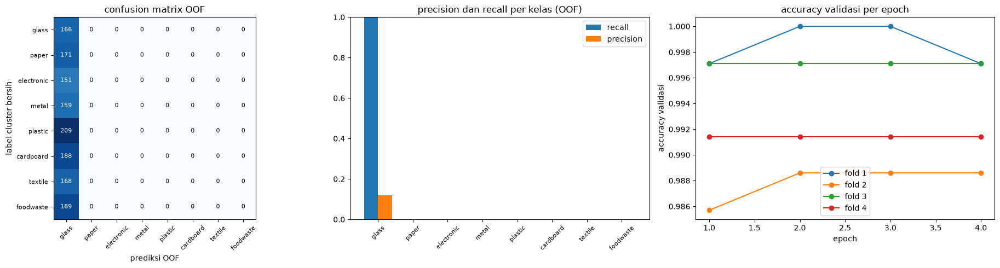

In [26]:
ACC_CV = np.array([(OOF[FOLD == f].argmax(1) == Y[FOLD == f]).mean() for f in SELESAI])
if len(ACC_CV):
    sd = ACC_CV.std(ddof=1) if len(ACC_CV) > 1 else float('nan')
    lp = np.array(ACC_LP)[SELESAI]
    print('accuracy per fold:', ACC_CV.round(4).tolist())
    print(f'accuracy CV ({len(ACC_CV)} dari {CFG.N_FOLD} fold): {ACC_CV.mean():.4f} +- {sd:.4f}')
    print(f'linear probe pada fold yang sama: {lp.mean():.4f} | selisih LoRA - linear probe per fold: {(ACC_CV - lp).round(4).tolist()}')
    for n in (145, 335):
        se = math.sqrt(ACC_CV.mean() * (1 - ACC_CV.mean()) / n)
        print(f'n = {n}: galat baku {se:.4f}, interval 95% kira-kira {ACC_CV.mean() - 1.96 * se:.3f} sampai {min(1, ACC_CV.mean() + 1.96 * se):.3f}')

    ada = np.isin(FOLD, SELESAI)
    yt, yp = Y[ada], OOF[ada].argmax(1)
    p, r, f1, n = precision_recall_fscore_support(yt, yp, labels=range(len(CFG.KELAS)), zero_division=0)
    tabel = pd.DataFrame({'precision': p, 'recall': r, 'f1': f1, 'n': n}, index=CFG.KELAS)
    for rata in ('macro', 'weighted'):
        tabel.loc[rata] = [*precision_recall_fscore_support(yt, yp, average=rata, zero_division=0)[:3], len(yt)]
    display(tabel.round(4))

    cm = confusion_matrix(yt, yp, labels=range(len(CFG.KELAS)))
    fig, ax = plt.subplots(1, 3, figsize=(19, 5))
    ax[0].imshow(cm, cmap='Blues')
    ax[0].set_xticks(range(len(CFG.KELAS)), CFG.KELAS, rotation=45, fontsize=8)
    ax[0].set_yticks(range(len(CFG.KELAS)), CFG.KELAS, fontsize=8)
    for i in range(len(CFG.KELAS)):
        for j in range(len(CFG.KELAS)):
            ax[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='w' if cm[i, j] > cm.max() / 2 else 'k')
    ax[0].set(xlabel='prediksi OOF', ylabel='label cluster bersih', title='confusion matrix OOF')
    x = np.arange(len(CFG.KELAS))
    ax[1].bar(x - 0.2, r, 0.4, label='recall')
    ax[1].bar(x + 0.2, p, 0.4, label='precision')
    ax[1].set_xticks(x, CFG.KELAS, rotation=45, fontsize=8)
    ax[1].set(ylim=(max(0, min(r.min(), p.min()) - 0.05), 1.0), title='precision dan recall per kelas (OOF)')
    ax[1].legend()
    for f, d in pd.DataFrame(RIW_CV).groupby('fold'):
        ax[2].plot(d.epoch, d.val_acc, marker='o', label=f'fold {f}')
    ax[2].set(xlabel='epoch', ylabel='accuracy validasi', title='accuracy validasi per epoch')
    ax[2].legend()
    plt.tight_layout()
    fig.savefig(CFG.FIG_DIR / 'validasi.png', dpi=100)
    plt.show()
else:
    print('belum ada fold selesai, metrik CV tidak tersedia')

#### Insights

> Isi setelah run: mean dan simpangan baku accuracy per fold, selisihnya terhadap linear probe, kelas dengan recall terendah, dan pasangan kelas yang paling sering tertukar di confusion matrix. Bila simpangan baku antar fold lebih dari sekitar 1,5 poin persen, selisih skor public dan private yang besar wajar terjadi. Bila kurva validasi masih naik di epoch terakhir, jumlah epoch mungkin terlalu sedikit, tetapi resep tidak diubah setelah melihat angka ini.

---

# Pseudo-label Train (Opsional) <a name="10"></a>

---

Bagian ini hanya berjalan bila `JALANKAN_PSEUDO = True`, setelah `submission.csv` aman. Model final memberi label pada 170 citra train tak berlabel (51 `campur` dan 119 yang dibuang aturan), dan hanya prediksi dengan probabilitas maksimum minimal `AMBANG_PSEUDO = 0,85` yang dipakai. Ambang ditetapkan sebelum run. Dengan label smoothing 0,1, probabilitas prediksi yang yakin berada di sekitar 0,91, jadi 0,85 hanya menerima prediksi yang jelas dominan. Pseudo-labeling hanya memakai train, sesuai QnA #22.3, dan label yang sudah ada tidak diganti. Satu model baru dilatih dengan resep yang sama, lalu prediksinya ditulis ke `submission_pseudo.csv` tanpa menimpa `submission.csv`.

Efek pseudo-label tidak divalidasi dengan CV karena butuh training tambahan untuk setiap fold. Citra tak berlabel adalah citra yang paling ragu, sehingga label semunya bisa menambah noise. Karena itu `submission.csv` tetap submission utama, dan keputusan memakai `submission_pseudo.csv` ada pada tim.

In [27]:
INFO_PSEUDO = None
if CFG.JALANKAN_PSEUDO:
    yakin = P_U.max(1) >= CFG.AMBANG_PSEUDO
    U_PL, Y_PL = U[yakin], P_U[yakin].argmax(1)
    print(f'pseudo-label: {int(yakin.sum())} dari {len(U)} citra train tak berlabel lolos ambang {CFG.AMBANG_PSEUDO}')
    print(pd.Series(np.array(CFG.KELAS)[Y_PL], dtype=object).value_counts().to_dict())
    t0 = time.time()
    RIW_PSEUDO, _ = latih_aman(np.r_[L, U_PL], np.r_[Y, Y_PL], nama='pseudo')
    simpan_adapter(CFG.OUTPUT_DIR / 'adapter_lora_pseudo.safetensors', {**INFO_ADAPTER, 'pseudo_label': int(yakin.sum())})
    P_TEST_PSEUDO = prediksi(X_test)
    np.save(CFG.OUTPUT_DIR / 'prob_test_pseudo.npy', P_TEST_PSEUDO)
    tulis_submission(P_TEST_PSEUDO, CFG.OUTPUT_DIR / 'submission_pseudo.csv')
    sama = float((P_TEST_PSEUDO.argmax(1) == P_TEST.argmax(1)).mean())
    INFO_PSEUDO = dict(n=int(yakin.sum()), jam=round((time.time() - t0) / 3600, 2), riwayat=RIW_PSEUDO, sama_dengan_utama=sama)
    print(f'submission_pseudo.csv siap | prediksi test sama dengan submission utama: {sama:.4f}')
else:
    print('pseudo-label dilewati (JALANKAN_PSEUDO = False)')

pseudo-label dilewati (JALANKAN_PSEUDO = False)


---

# Ringkasan Run <a name="11"></a>

---

Ringkasan run disimpan ke `ringkasan_run.json` untuk laporan: versi pustaka dan GPU, mode bobot, resolusi dan batch terpilih, waktu tiap tahap, riwayat training, linear probe, cross-validation, dan sebaran prediksi test. Berkas yang diunggah tim adalah `keluaran_7b/submission.csv`.

In [28]:
RINGKASAN = dict(
    gpu=INFO_GPU, mode=MUAT, konfigurasi=PILIHAN, ukuran=UKURAN, bs_mikro=BS_MIKRO, akumulasi=AKUM,
    lora=dict(r=CFG.LORA_R, alpha=CFG.LORA_ALPHA, dropout=CFG.LORA_DROPOUT, lapis=n_modul, parameter_latih=n_latih),
    detik_muat=round(DETIK_MUAT), detik_fitur=round(DETIK_FITUR), jam_final=round(JAM_FINAL, 2), riwayat_final=RIW_FINAL,
    linear_probe=dict(per_fold=ACC_LP, mean=float(np.mean(ACC_LP)), std=float(np.std(ACC_LP, ddof=1))),
    cv=dict(fold=SELESAI, per_fold=ACC_CV.tolist(), mean=float(ACC_CV.mean()) if len(ACC_CV) else None,
            std=float(ACC_CV.std(ddof=1)) if len(ACC_CV) > 1 else None),
    submission=SUB.waste_category.value_counts().to_dict(), pseudo=INFO_PSEUDO)
with open(CFG.OUTPUT_DIR / 'ringkasan_run.json', 'w', encoding='utf-8') as fh:
    json.dump(RINGKASAN, fh, indent=1, default=str)
print(json.dumps(RINGKASAN, indent=1, default=str))
print('berkas keluaran:', sorted(p.name for p in CFG.OUTPUT_DIR.iterdir()))

{
 "gpu": {
  "gpu": "NVIDIA GeForce RTX 5090",
  "kapabilitas": "sm_120",
  "vram_gib": 31.4,
  "python": "3.12.15",
  "torch": "2.14.1+cu130",
  "cuda_torch": "13.0",
  "cudnn": 92400,
  "bitsandbytes": "0.50.2",
  "timm": "1.0.29",
  "peft": "0.21.3",
  "arsitektur_build": "sm_75 sm_80 sm_86 sm_90 sm_100 sm_120"
 },
 "mode": "nf4",
 "konfigurasi": {
  "ukuran": 384,
  "bs_mikro": 16,
  "detik_per_citra": 0.23182770609855652,
  "vram_gib": 12.4,
  "jam_final": 0.52
 },
 "ukuran": 384,
 "bs_mikro": 16,
 "akumulasi": 1,
 "lora": {
  "r": 16,
  "alpha": 32,
  "dropout": 0.05,
  "lapis": 200,
  "parameter_latih": 39387144
 },
 "detik_muat": 17,
 "detik_fitur": 146,
 "jam_final": 0.46,
 "riwayat_final": [
  {
   "epoch": 1,
   "loss": 0.6424,
   "detik": 415
  },
  {
   "epoch": 2,
   "loss": 0.4896,
   "detik": 415
  },
  {
   "epoch": 3,
   "loss": 0.4813,
   "detik": 415
  },
  {
   "epoch": 4,
   "loss": 0.4791,
   "detik": 414
  }
 ],
 "linear_probe": {
  "per_fold": [
   0.991452991

#### Insights

> Isi setelah run: resolusi dan mode bobot yang benar-benar dipakai, waktu model final, accuracy CV dengan simpangan bakunya, dan perbandingannya dengan linear probe. Semua angka di laporan diambil dari `ringkasan_run.json`, bukan dari perkiraan di sel markdown.

> Submission berasal dari satu model DINOv3 ViT-7B dengan adapter LoRA yang dilatih pada seluruh label bersih. Tidak ada ensemble, rata-rata fold, TTA, atau pseudo-label dari test.